# Excel sensor list: what the data says about each sensor

**Input:** `sensors displayed in the visualization tool.xlsx` (the tags shown in the visualization tool) and the 39 logged days in `02_data/downsampled/*_10s.parquet` (2025-10-30 → 2026-03-30).

**Questions**
1. Can every Excel tag be found in the logged data, and under which column name?
2. Is each sensor's data usable: is it present, does it move, are there `-1` fills, glitches or stuck values?
3. How does each sensor behave in each stage, and how strongly does the stage show up in it?
4. How many sensors carry *independent* information, and which are near-copies of each other?
5. Verdict per tag: key / useful / low value / back-up twin / limited / not usable.

Stage labels come from `04_synthetic_data/library/traces_1min.parquet` (rules of 2026-10-15, `operating_states.py`). Tag → column tracing follows `component_sensor_map_en.md` §3.2 and the earlier check in `03_data_analysis/sensor_trace/`. Outputs go to `03_data_analysis/excel_sensors/`.

**Result in short** (details in §9)
- 255 rows = 253 distinct tags (`TIRC 3,17` and `EIRC 2,01` are listed twice). 254 are found in the raw data (201 same name, 35 under another name, 18 best match); only `LIR 7,01` is not logged.
- 43 tags are not usable: 40 EIR package voltages read ≈ 0 V, `TIR 4,6,19` is stuck at 1300 °C, `TIR 4,6,25` reads ≈ 36 °C inside a 400–600 °C stack, `EIRC 4,1,8` never moves. 21 more have real values only part of the time.
- The sensors are strongly linked: 107 of 209 usable sensors follow the stack temperature with |r| ≥ 0.8. They form only 56 independent groups (75 in hot operation).
- The raw data has 38 measurement columns that are not on the Excel list, among them a stack-4 voltage per string and three room climate sensors that could serve as the missing ambient temperature.

In [1]:
import glob
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import openpyxl
import pandas as pd
import pyarrow.parquet as pq
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == "03_data_analysis" else Path.cwd()
OUT = ROOT / "03_data_analysis" / "excel_sensors"
OUT.mkdir(parents=True, exist_ok=True)
FILES = sorted(glob.glob(str(ROOT / "02_data" / "downsampled" / "*_10s.parquet")))
STAGES = ["Idle", "Start-up", "Hot standby", "Thermal adjustment", "Part load", "Shut-down"]
STAGE_COLORS = {"Idle": "#999999", "Start-up": "#E69F00", "Hot standby": "#D55E00", "Thermal adjustment": "#CC79A7",
                "Part load": "#009E73", "Shut-down": "#56B4E9"}
pd.set_option("display.max_colwidth", 80, "display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print(len(FILES), "day files:", Path(FILES[0]).name, "→", Path(FILES[-1]).name)

39 day files: 20251030_10s.parquet → 20260330_10s.parquet


## 1. Read the Excel list and trace each tag to a logged column

Naming rules (Excel → logger):
- `TIR 4,6,1` → `TIR_4_6_1` (same for TIR, TIRC, TIRZ, PIR, PIRZ)
- `FIRC 1,1,1` → `ct_FIRC_111_PV_ProcessValue` (flow actual value)
- `EIRC 4,s,k` (electronic load of string s) → the PLC host columns `PLC_hostSetp_ctrl_ctEIRC4s_…` (k = 1 voltage, 2 current, 4 set-point, 5 slew rate, 6 mode, 9 lowest cell voltage) or `EIRC_4s_…` (k = 3 power, 7 on/off, 8 device status; these are logged only from 2026-03-17)
- `EIR 4,s,k` → `pi_EIR_4_s_k` (k = 12/15/18/21 stack voltages, the others package voltages)
- `EIRC 2,01` → EAPH 3-phase power; `EIRC 3,x / 5,x` → heater currents `pi_IIR_…` (assumed match)
- `TIRC 3,19,x` → logged as `TIR_3_19_x`; `QIR 1,4` → `PLC_pi_QIR_1_4_ActVal_Value`

In [2]:
ws = openpyxl.load_workbook(ROOT / "01_docs" / "sensors displayed in the visualization tool.xlsx").active
rows = []
for r in ws.iter_rows(min_row=4):
    if r[0].value is None:
        continue
    rows.append(dict(sno=int(r[0].value), tag=re.sub(r"\s+", " ", str(r[1].value or "").strip())))
tags = pd.DataFrame(rows)
tags["duplicate_of"] = tags.groupby("tag").sno.transform("first").where(lambda s: s != tags.sno)

present = {}
for f in FILES:
    for c in pq.read_schema(f).names:
        present[c] = present.get(c, 0) + 1
cols = set(present)

EIRC4 = {1: ("PLC_hostSetp_ctrl_ctEIRC4{s}_rVoltMonitor", "other name", "string load voltage"),
         2: ("PLC_hostSetp_ctrl_ctEIRC4{s}_rCurrMonitor", "other name", "string load current"),
         3: ("EIRC_4{s}_Actual_Power", "assumed", "string load power"),
         4: ("PLC_hostSetp_ctrl_ctEIRC4{s}_SP_TargetValue_Value", "other name", "current set-point"),
         5: ("PLC_hostSetp_ctrl_ctEIRC4{s}_SP_SlewRateAbs", "other name", "slew-rate setting"),
         6: ("PLC_hostSetp_ctrl_ctEIRC4{s}_OpMode", "other name", "load operating mode"),
         7: ("EIRC_4{s}_OUT_Enable", "other name", "load on/off"),
         8: ("EIRC_4{s}_OUT_StackCon_OnOff)", "assumed", "load device status"),
         9: ("PLC_hostSetp_ctrl_ctEIRC4{s}_rVoltCellMin_ActV", "assumed", "lowest cell voltage")}
EIR_STACK = {12: 1, 15: 2, 18: 3, 21: 4}


def trace(tag):
    m = re.match(r"^([A-Z]+)\s*([\d,]*)$", tag)
    if not m or not m.group(2):
        return None, "none", "blank tag name"
    fam, nums = m.group(1), [n for n in m.group(2).split(",") if n]
    us = "_".join(nums)
    if fam == "FIRC":
        return f"ct_FIRC_{''.join(nums)}_PV_ProcessValue", "direct", "flow"
    if fam == "QIR":
        return "PLC_pi_QIR_1_4_ActVal_Value", "other name", "natural-gas quality"
    if fam == "EIRC" and us == "2_01":
        return "EIRC_2_01_ActV_In_ThreePhasePower", "other name", "EAPH heater power"
    if fam == "EIRC" and nums[0] in ("3", "5"):
        return f"pi_IIR_{us}_ActVal", "assumed", "heater current"
    if fam == "EIRC" and nums[0] == "4":
        c, how, note = EIRC4[int(nums[2])]
        return c.format(s=nums[1]), how, note
    if fam == "EIR":
        k = int(nums[2])
        return f"pi_EIR_{us}", "direct", f"stack {EIR_STACK[k]} voltage" if k in EIR_STACK else "package voltage"
    if fam == "TIRC" and us.startswith("3_19"):
        return f"TIR_{us}", "other name", "logged as TIR"
    return f"{fam}_{us}", "direct", ""


tags["column"], tags["how"], tags["meaning"] = zip(*tags.tag.apply(trace))
miss = tags.column.notna() & ~tags.column.isin(cols)
tags.loc[miss, ["how", "meaning"]] = ["none", "no such column in the 836 logged columns"]
tags.loc[tags.how == "none", "column"] = None
tags["family"] = tags.tag.str.extract(r"^([A-Z]+)")[0].fillna("")
tags["kind"] = tags.family.str[0].map({"T": "Temperature", "P": "Pressure", "F": "Flow", "E": "Electrical",
                                       "L": "Level", "Q": "Gas quality"}).fillna("(blank)")
first = tags.tag.str.extract(r"^[A-Z]+\s*(\d+)")[0]
AREA = {"1": "Gas & air supply", "2": "Air pre-heating", "3": "Reformer / gas prep.", "4": "Stack",
        "5": "Off-gas & after-burner", "6": "Anode recycle", "7": "Exhaust & heat recovery", "8": "Safety monitors"}
tags["area"] = first.map(AREA).fillna("-")
tags.loc[tags.family.isin(["EIR", "EIRC"]) & (first == "4"), "area"] = "Stack electrical"
tags.loc[tags.family.eq("EIRC") & first.isin(["2", "3", "5"]), "area"] = "Heater power"
tags["days_logged"] = tags.column.map(present).fillna(0).astype(int)

print(f"{len(tags)} rows, {tags.tag.nunique()} distinct tag names, duplicates: "
      f"{tags.loc[tags.duplicate_of.notna(), 'tag'].tolist()}")
display(pd.crosstab(tags.area, tags.kind, margins=True, margins_name="Total"))
display(tags.how.value_counts().rename("rows").to_frame())
display(tags[tags.how == "none"][["sno", "tag", "meaning"]])
print("Logged on fewer than 39 days:")
display(tags[(tags.days_logged > 0) & (tags.days_logged < 39)].groupby("days_logged").tag.apply(list).to_frame())

255 rows, 253 distinct tag names, duplicates: ['TIRC 3,17', 'EIRC 2,01']


kind,Electrical,Flow,Gas quality,Level,Pressure,Temperature,Total
area,,,,,,,
Air pre-heating,0,0,0,0,2,6,8
Anode recycle,0,0,0,0,1,2,3
Exhaust & heat recovery,0,0,0,1,4,8,13
Gas & air supply,0,7,1,0,10,6,24
Heater power,5,0,0,0,0,0,5
Off-gas & after-burner,0,0,0,0,8,22,30
Reformer / gas prep.,0,0,0,0,3,22,25
Safety monitors,0,0,0,0,1,9,10
Stack,0,0,0,0,0,37,37


,rows
how,
direct,201
other name,35
assumed,18
none,1


,sno,tag,meaning
33,34,"LIR 7,01",no such column in the 836 logged columns


Logged on fewer than 39 days:


,tag
days_logged,
12,"[FIRC 1,1,3, EIRC 4,1,3, EIRC 4,1,7, EIRC 4,1,8, EIRC 4,2,3, EIRC 4,2,7, EIR..."


## 1b. Excel name → name in the raw dataset

The raw files `02_data/raw/<day>.txt` are tab-separated with one header line. Their column names are the names used everywhere downstream (1-s parquet, 10-s downsampled files). This table reads the headers of all 39 raw files directly and gives, for each Excel row:
- **raw_column**: the raw column that carries the measured value
- **match**: `direct` (same name, `,` → `_`), `other name` (documented in `component_sensor_map_en.md` §3.2 or the PLC naming), `assumed` (best candidate, not documented), `none`
- **raw_days**: number of raw files that contain the column
- **related_raw_columns**: other raw columns for the same tag (set-point, controller output, enable, safety twin, an older name)

In [3]:
RAW = ROOT / "02_data" / "raw"
raw_days = {}
for f in sorted(RAW.glob("*.txt")):
    with open(f, "rb") as fh:
        head = fh.readline().decode("utf-8", errors="replace").rstrip("\r\n").split("\t")
    for c in head:
        raw_days.setdefault(c, set()).add(f.stem)
raw_cols = sorted(raw_days)
print(len(list(RAW.glob('*.txt'))), "raw files,", len(raw_cols), "distinct raw column names")


def related(tag):
    m = re.match(r"^([A-Z]+)\s*([\d,]*)$", tag)
    if not m or not m.group(2):
        return []
    fam, nums = m.group(1), [n for n in m.group(2).split(",") if n]
    us, cat = "_".join(nums), "".join(nums)
    if fam == "EIRC" and nums[0] == "4":
        keys = [f"EIRC4{nums[1]}_", f"EIRC_4{nums[1]}_"]
        suffix = {1: "Volt", 2: "Curr", 3: "Power", 4: "TargetValue", 5: "SlewRate", 6: "OpMode", 7: "Enable",
                  8: "StackCon", 9: "CellMin"}[int(nums[2])]
        return [c for c in raw_cols if any(k in c for k in keys) and suffix.lower() in c.lower()]
    base = fam.rstrip("CZ") if fam not in ("FIRC", "EIRC", "QIR") else fam
    keys = {f"{fam}_{us}", f"{fam}_{cat}", f"{base}_{us}", f"{base}C_{us}", f"{base}Z_{us}"}
    if fam == "EIRC" and nums[0] in ("3", "5"):
        keys |= {f"IIR_{us}"}
    hit = []
    for c in raw_cols:
        for k in keys:
            i = c.find(k)
            if i >= 0 and (i + len(k) == len(c) or not c[i + len(k)].isdigit()) and (i == 0 or not c[i - 1].isalnum() or c[i - 1] == "_"):
                hit.append(c)
                break
    return hit


tags["raw_column"] = tags.column.where(tags.column.isin(raw_cols))
tags["raw_days"] = tags.raw_column.map(lambda c: len(raw_days.get(c, ())) if isinstance(c, str) else 0)
tags["related_raw_columns"] = [", ".join(c for c in related(t) if c != rc) for t, rc in zip(tags.tag, tags.raw_column)]
NAME_MAP = tags[["sno", "tag", "raw_column", "how", "meaning", "raw_days", "related_raw_columns"]].rename(columns={"how": "match"})
NAME_MAP.to_csv(OUT / "excel_to_raw_names.csv", index=False)
print(NAME_MAP.match.value_counts().to_string())
with pd.option_context("display.max_rows", 300, "display.max_colwidth", 70):
    display(NAME_MAP)

39 raw files, 836 distinct raw column names
match
direct        201
other name     35
assumed        18
none            1


,sno,tag,raw_column,match,meaning,raw_days,related_raw_columns
0,1,"PIR 1,1,1",PIR_1_1_1,direct,,39,
1,2,"FIRC 1,1,1",ct_FIRC_111_PV_ProcessValue,direct,flow,39,"ct_FIRC_111_DO_SlewRateAbs, ct_FIRC_111_DO_TargetValue, ct_FIRC_11..."
2,3,"TIR 1,1,1",TIR_1_1_1,direct,,39,
3,4,"FIRC 1,1,3",ct_FIRC_113_PV_ProcessValue,direct,flow,12,"PLC_ctrl_ct_FIRC_113_OUT_Analog, PLC_ctrl_ct_FIRC_113_OUT_EnableSi..."
4,5,"PIR 1,1,2",PIR_1_1_2,direct,,39,
5,6,"PIR 1,1,3",PIR_1_1_3,direct,,39,
6,7,"FIRC 1,1,2",ct_FIRC_112_PV_ProcessValue,direct,flow,39,"ct_FIRC_112_DO_SlewRateAbs, ct_FIRC_112_DO_TargetValue, ct_FIRC_11..."
7,8,"PIRZ 8,1,2",PIRZ_8_1_2,direct,,39,
8,9,"QIR 1,4",PLC_pi_QIR_1_4_ActVal_Value,other name,natural-gas quality,39,PLC_pv_QIR_1_4_calc
9,10,"PIR 1,4,1",PIR_1_4_1,direct,,39,


**Raw measurement columns that are not in the Excel list.** Only measurement-style names (TIR/TIRC/TIRZ, PIR/PIRZ, FIRC process value, EIR, IIR, QIR, EIRC monitors) are checked; set-points, valves, insulation monitors and PLC status bits are left out.

In [4]:
meas = re.compile(r"^(TIRZ?C?|PIRZ?)_\d|^ct_FIRC_\d+_PV_ProcessValue$|^pi_EIR_|^pi_IIR_|QIR|^EIRC_\d+_(ActV|CurrentMon|VoltageMon|Actual_Power)")
listed = set(tags.raw_column.dropna())
extra = [c for c in raw_cols if meas.search(c) and c not in listed]
EX = pd.DataFrame({"raw_column": extra, "raw_days": [len(raw_days[c]) for c in extra]})
print(len(EX), "measurement columns in the raw data are not on the Excel list")
with pd.option_context("display.max_rows", 200):
    display(EX)
EX.to_csv(OUT / "raw_not_in_excel.csv", index=False)

38 measurement columns in the raw data are not on the Excel list


,raw_column,raw_days
0,EIRC_41_ActV_Min_CellVoltage,12
1,EIRC_41_CurrentMon,12
2,EIRC_41_VoltageMon,12
3,EIRC_42_ActV_Min_CellVoltage,12
4,EIRC_42_CurrentMon,12
5,EIRC_42_VoltageMon,12
6,EIRC_43_ActV_Min_CellVoltage,12
7,EIRC_43_CurrentMon,12
8,EIRC_43_VoltageMon,12
9,EIRC_44_ActV_Min_CellVoltage,12


## 2. Load the data as 1-minute means

Values above 1e30 (the logger's “invalid” marker, e.g. 3e37) are counted as glitches and blanked. `-1` is kept here and counted separately (it is the fill value for an unconnected channel). The result is cached in `excel_sensors/x1min.parquet`.

In [5]:
use = sorted(set(tags.column.dropna()))
cache = OUT / "x1min.parquet"
if cache.exists() and set(use) <= set(pq.read_schema(cache).names):
    X = pd.read_parquet(cache)
    glitch = pd.read_csv(OUT / "glitches.csv", index_col=0).iloc[:, 0]
else:
    frames, glitch = [], pd.Series(0.0, index=use)
    for f in FILES:
        have = [c for c in use if c in pq.read_schema(f).names]
        d = pd.read_parquet(f, columns=["Date Time"] + have).set_index("Date Time").apply(pd.to_numeric, errors="coerce")
        big = d.abs() > 1e30
        glitch = glitch.add(big.sum(), fill_value=0)
        frames.append(d.mask(big).resample("1min").mean())
    X = pd.concat(frames).reindex(columns=use)
    lab = pd.read_parquet(ROOT / "04_synthetic_data" / "library" / "traces_1min.parquet")[["stage", "phase"]]
    X = X.join(lab, how="left")
    X.to_parquet(cache)
    glitch.rename("glitches").to_csv(OUT / "glitches.csv")
num = X[use]
print("minutes:", len(X), "| columns:", len(use), "| labelled minutes:", X.stage.isin(STAGES).sum())
print("hours per stage:", (X.stage.value_counts() / 60).round(1).to_dict())

minutes: 55584 | columns: 252 | labelled minutes: 54810
hours per stage: {'Shut-down': 396.1, 'Hot standby': 297.3, 'Start-up': 148.9, 'Thermal adjustment': 45.8, 'Idle': 21.0, 'Part load': 4.5}


## 3. Data quality per sensor

Per column:
- **coverage**: share of logged minutes with a value
- **minus1_share**: share of minutes reading exactly `-1` (unconnected / fill)
- **glitches**: count of 10-s values above 1e30
- **p01 / median / p99**: range without `-1`
- **days_moving**: days on which the value moves by more than 1 % of its overall range (1st–99th percentile)
- **first_moving / last_moving**: first and last such day
- **noise_rel**: typical minute-to-minute change as a share of the range (high = noisy)

In [6]:
logged = num.notna().any(axis=1)
day = num.index.normalize()
lab_ok = X.stage.isin(STAGES)
daily, res = {}, {}
for c in use:
    s = num[c]
    v = s.where(s != -1)
    p01, p50, p99 = v.quantile([.01, .5, .99]) if v.notna().any() else (np.nan,) * 3
    span = p99 - p01
    tol = max(1e-6, 0.01 * span) if np.isfinite(span) and span > 0 else 1e-6
    dspan = v.groupby(day).quantile(.99) - v.groupby(day).quantile(.01)
    daily[c] = pd.DataFrame({"span": dspan, "median": v.groupby(day).median(),
                             "minus1": (s == -1).groupby(day).mean(), "cov": s.notna().groupby(day).mean()})
    alive = dspan > tol
    fm = alive[alive].index.min() if alive.any() else None
    pre = s[logged & (s.index < fm)] if fm is not None else s[logged]
    pre_bad = float(((pre == -1) | pre.isna()).mean()) if len(pre) else 0.0
    real_days = int((v.groupby(day).median().abs() > .5).sum())
    g = v[lab_ok].groupby(X.stage[lab_ok])
    tot = v[lab_ok].var(ddof=0)
    eta = float(((g.mean() - v[lab_ok].mean()) ** 2 * g.count()).sum() / (tot * g.count().sum())) if tot and tot > 0 else 0.0
    med = g.median()
    res[c] = dict(coverage=s[logged].notna().mean(), minus1_share=(s == -1).mean(), glitches=int(glitch.get(c, 0)),
                  n_unique=int(v.round(6).nunique()), p01=p01, median=p50, p99=p99, span=span,
                  days_moving=int(alive.sum()),
                  first_moving=alive[alive].index.min() if alive.any() else pd.NaT,
                  last_moving=alive[alive].index.max() if alive.any() else pd.NaT,
                  pre_bad=pre_bad, real_days=real_days,
                  noise_rel=(v.diff().abs().median() / span) if span and span > 0 else np.nan,
                  eta2_stage=eta, **{f"med_{k}": med.get(k, np.nan) for k in STAGES})
M = pd.DataFrame(res).T
for k in ["pre_bad", "coverage", "minus1_share", "p01", "median", "p99", "span", "noise_rel", "eta2_stage"] + [f"med_{k}" for k in STAGES]:
    M[k] = M[k].astype(float)
D = pd.concat(daily, names=["column", "day"])
D.to_parquet(OUT / "daily.parquet")
T = tags.merge(M, left_on="column", right_index=True, how="left")
q = T[T.column.notna()]
print("coverage ≥ 95 %:", (q.coverage >= .95).sum(), "of", len(q))
print("tags with any -1 fill:", (q.minus1_share > 0).sum(), "| with glitches:", (q.glitches > 0).sum())
print("never move (days_moving = 0):", (q.days_moving == 0).sum())
display(q.groupby("area")[["coverage", "days_moving"]].median().round(2))

coverage ≥ 95 %: 238 of 254
tags with any -1 fill: 203 | with glitches: 4
never move (days_moving = 0): 0


,coverage,days_moving
area,,
Air pre-heating,1.0,35.5
Anode recycle,1.0,38.0
Exhaust & heat recovery,1.0,37.0
Gas & air supply,1.0,33.0
Heater power,1.0,31.0
Off-gas & after-burner,1.0,36.0
Reformer / gas prep.,1.0,37.0
Safety monitors,1.0,37.0
Stack,1.0,35.0


### 3.1 Which sensors move on which day

One row per traced tag (sorted by plant area), one column per logged day. Dark = the sensor moves that day; light = flat; white = no data; red = mostly `-1`. This shows dead channels, channels that come alive later, and days when the whole plant was off (every row light).

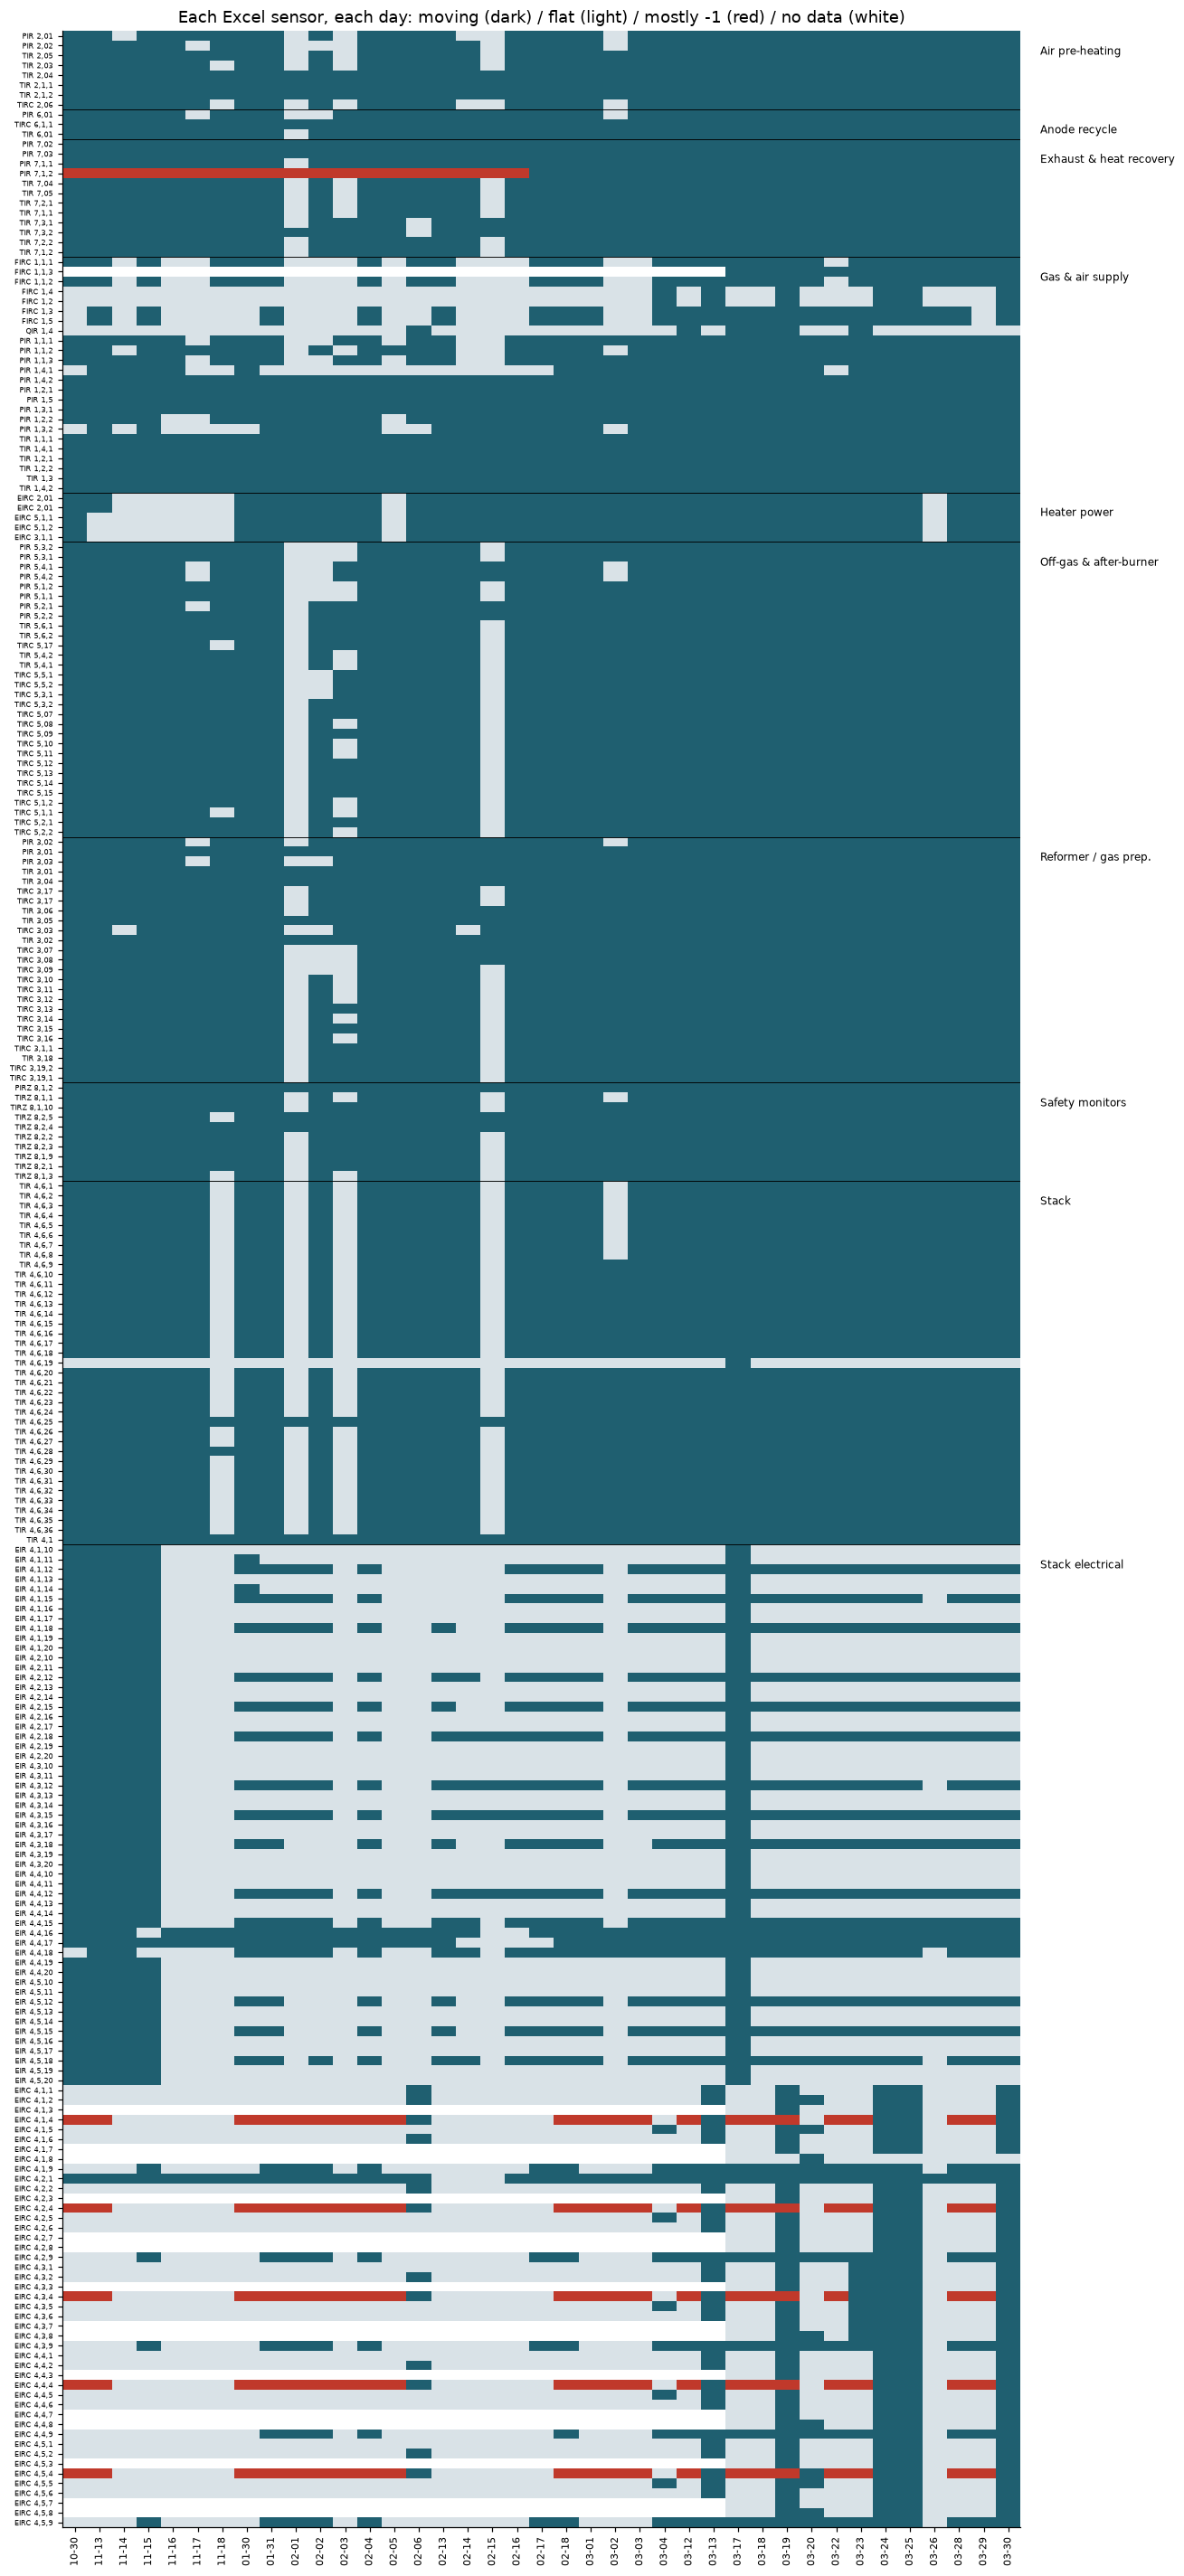

In [7]:
def state(c):
    d = D.loc[c].reindex(sorted(set(day)))
    tol = max(1e-6, 0.01 * M.at[c, "span"]) if M.at[c, "span"] > 0 else 1e-6
    z = np.where(d["cov"].fillna(0) < .05, 0, np.where(d["minus1"] > .5, 3, np.where(d["span"] > tol, 2, 1)))
    return z


order = q.sort_values(["area", "kind", "sno"])
Z = np.vstack([state(c) for c in order.column])
days_ = sorted(set(day))
from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(12, 26))
ax.imshow(Z, aspect="auto", cmap=ListedColormap(["#ffffff", "#d9e2e7", "#1f5f70", "#c0392b"]), vmin=0, vmax=3,
          interpolation="nearest")
ax.set_yticks(range(len(order)), order.tag, fontsize=5.5)
ax.set_xticks(range(len(days_)), [d.strftime("%m-%d") for d in days_], rotation=90, fontsize=7)
edges = np.flatnonzero(order.area.values[1:] != order.area.values[:-1])
for e in edges:
    ax.axhline(e + .5, color="k", lw=.6)
for e, a in zip(np.r_[-1, edges], order.area.unique()):
    ax.text(len(days_) + .3, e + 2, a, fontsize=8, va="top")
ax.set_title("Each Excel sensor, each day: moving (dark) / flat (light) / mostly -1 (red) / no data (white)")
plt.tight_layout()
fig.savefig(OUT / "days_moving.png", dpi=130)
plt.show()

### 3.2 Sensors with a data problem

Flagged automatically:
- **dead**: moves on fewer than 3 days
- **mostly -1**: more than 50 % of minutes read `-1`
- **late start**: first moving day after 2026-01-01 *and* the time before reads `-1` or blank (a channel connected late; a value that is a valid 0 before, e.g. natural gas before March, is not flagged)
- **near zero**: an EIR voltage whose daily median is above 0.5 V on 3 days or fewer (unscaled or unconnected channel)
- **glitches**: invalid values (> 1e30) in the 10-s data
- **outlier channel**: a stack thermocouple whose median is far from the other stack thermocouples

In [8]:
stack_tc = q[q.tag.str.match(r"TIR 4,6,")]
tc_med = stack_tc.set_index("tag")["median"]
p = []
for _, r in q.iterrows():
    why = []
    if r.days_moving < 3:
        why.append(f"dead: moves on {r.days_moving} days")
    if r.minus1_share > .5:
        why.append(f"mostly -1 ({r.minus1_share:.0%} of minutes)")
    elif r.minus1_share > .02:
        why.append(f"-1 fill on {r.minus1_share:.0%} of minutes")
    if pd.notna(r.first_moving) and r.first_moving > pd.Timestamp("2026-01-01") and r.days_logged == 39 and r.pre_bad > .5:
        why.append(f"real values only from {r.first_moving:%Y-%m-%d} (-1 or blank before)")
    if r.family == "EIR" and r.real_days <= 3:
        why.append(f"near zero: median {r['median']:.4f} V; above 0.5 V on only {r.real_days} days")
    if r.days_logged < 39:
        why.append(f"logged on {r.days_logged} of 39 days")
    if r.glitches > 0:
        why.append(f"{r.glitches} invalid values")
    if r.tag in tc_med and abs(r["median"] - tc_med.median()) > 150:
        why.append(f"median {r['median']:.0f} °C vs {tc_med.median():.0f} °C for the other stack thermocouples")
    if r.tag.startswith("TIR") and r.n_unique <= 3:
        why.append(f"only {r.n_unique} distinct values (stuck)")
    if why:
        p.append(dict(sno=r.sno, tag=r.tag, area=r.area, column=r.column, problem="; ".join(why),
                      p01=round(r.p01, 3), median=round(r["median"], 3), p99=round(r.p99, 3)))
P = pd.DataFrame(p)
BAD = set(P[P.problem.str.contains("dead|stuck|near zero| vs ", regex=True)].tag)
print(len(P), "tags with a flagged problem;", len(BAD), "of them unusable (dead, stuck, near zero, outlier)")
display(P)

65 tags with a flagged problem; 43 of them unusable (dead, stuck, near zero, outlier)


,sno,tag,area,column,problem,p01,median,p99
0,4,"FIRC 1,1,3",Gas & air supply,ct_FIRC_113_PV_ProcessValue,logged on 12 of 39 days,22.300,441.920,592.452
1,49,"PIR 7,1,2",Exhaust & heat recovery,PIR_7_1_2,mostly -1 (50% of minutes); real values only from 2026-02-17 (-1 or blank be...,0.000,4.568,9.619
2,128,"TIR 4,6,19",Stack,TIR_4_6_19,dead: moves on 1 days; median 1300 °C vs 407 °C for the other stack thermoco...,1300.000,1300.000,1300.000
3,134,"TIR 4,6,25",Stack,TIR_4_6_25,median 36 °C vs 407 °C for the other stack thermocouples,1.800,35.613,66.636
4,152,"EIR 4,1,10",Stack electrical,pi_EIR_4_1_10,near zero: median 0.0057 V; above 0.5 V on only 2 days,0.004,0.006,5.451
...,...,...,...,...,...,...,...,...
60,245,"EIRC 4,5,3",Stack electrical,EIRC_45_Actual_Power,logged on 12 of 39 days,0.000,0.000,2.188
61,246,"EIRC 4,5,4",Stack electrical,PLC_hostSetp_ctrl_ctEIRC45_SP_TargetValue_Value,mostly -1 (58% of minutes); real values only from 2026-02-06 (-1 or blank be...,0.000,0.000,21.085
62,249,"EIRC 4,5,7",Stack electrical,EIRC_45_OUT_Enable,logged on 12 of 39 days,0.000,0.000,1.000
63,250,"EIRC 4,5,8",Stack electrical,EIRC_45_OUT_StackCon_OnOff),logged on 12 of 39 days,0.000,0.000,1.000


## 4. How each sensor behaves in each stage

**η² (eta squared)** = share of a sensor's variation explained by the stage label (0 = the stage tells you nothing about the value, 1 = the value is fully set by the stage). It is computed on the labelled minutes with `-1` removed.

In [9]:
good = q[~q.tag.isin(BAD)]
top = good.sort_values("eta2_stage", ascending=False)
print("median η² by area:")
display(good.groupby("area").eta2_stage.agg(["median", "max", "count"]).round(2).sort_values("median", ascending=False))
display(top[["sno", "tag", "area", "meaning", "eta2_stage"] + [f"med_{k}" for k in STAGES]].head(25).round(2))

median η² by area:


,median,max,count
area,,,
Heater power,0.66,0.66,5
Safety monitors,0.61,0.71,10
Stack,0.60,0.65,35
Off-gas & after-burner,0.60,0.71,30
Stack electrical,0.56,0.87,59
Reformer / gas prep.,0.53,0.68,25
Anode recycle,0.50,0.52,3
Air pre-heating,0.44,0.66,8
Exhaust & heat recovery,0.38,0.60,12


,sno,tag,area,meaning,eta2_stage,med_Idle,med_Start-up,med_Hot standby,med_Thermal adjustment,med_Part load,med_Shut-down
212,213,"EIRC 4,1,7",Stack electrical,load on/off,0.87,NaN,0.00,0.00,0.00,1.00,0.00
221,222,"EIRC 4,2,7",Stack electrical,load on/off,0.87,NaN,0.00,0.00,0.00,1.00,0.00
239,240,"EIRC 4,4,7",Stack electrical,load on/off,0.87,NaN,0.00,0.00,0.00,1.00,0.00
222,223,"EIRC 4,2,8",Stack electrical,load device status,0.87,NaN,0.00,0.00,0.00,1.00,0.00
248,249,"EIRC 4,5,7",Stack electrical,load on/off,0.87,NaN,0.00,0.00,0.00,1.00,0.00
238,239,"EIRC 4,4,6",Stack electrical,load operating mode,0.86,0.00,0.00,0.00,0.00,3.00,0.00
220,221,"EIRC 4,2,6",Stack electrical,load operating mode,0.86,0.00,0.00,0.00,0.00,3.00,0.00
247,248,"EIRC 4,5,6",Stack electrical,load operating mode,0.86,0.00,0.00,0.00,0.00,3.00,0.00
211,212,"EIRC 4,1,6",Stack electrical,load operating mode,0.86,0.00,0.00,0.00,0.00,3.00,0.00
233,234,"EIRC 4,4,1",Stack electrical,string load voltage,0.85,0.00,0.00,0.00,0.00,454.50,0.00


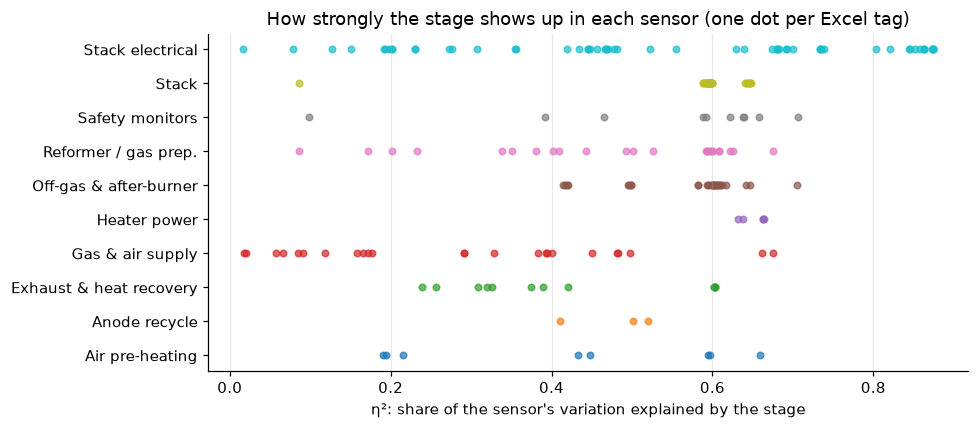

In [10]:
fig, ax = plt.subplots(figsize=(9, 4))
for a, g in good.groupby("area"):
    ax.scatter(g.eta2_stage, [a] * len(g), s=18, alpha=.7)
ax.set_xlabel("η²: share of the sensor's variation explained by the stage")
ax.set_title("How strongly the stage shows up in each sensor (one dot per Excel tag)")
ax.grid(axis="x", alpha=.3)
plt.tight_layout()
fig.savefig(OUT / "eta2_by_area.png", dpi=130)
plt.show()

### 4.1 Stage profile of one representative per area

Each row is scaled to its own range (0 = lowest stage median, 1 = highest), so the pattern across stages can be compared between sensors with different units.

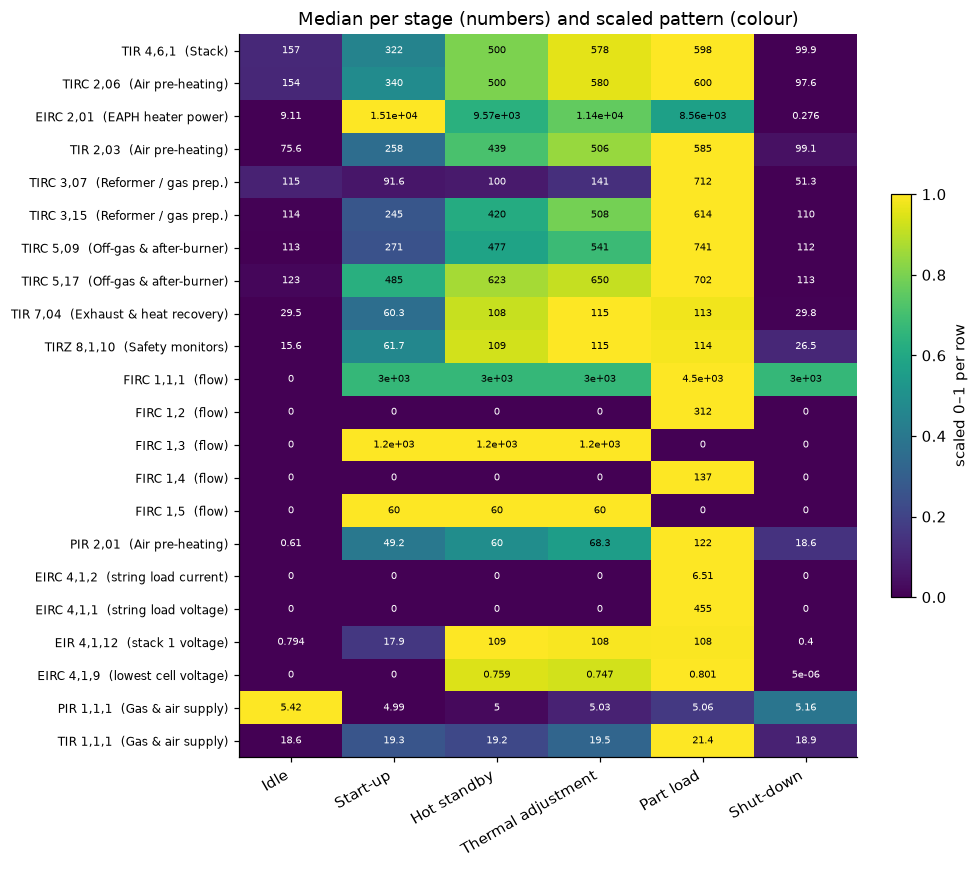

In [11]:
REP = ["TIR 4,6,1", "TIRC 2,06", "EIRC 2,01", "TIR 2,03", "TIRC 3,07", "TIRC 3,15", "TIRC 5,09", "TIRC 5,17",
       "TIR 7,04", "TIRZ 8,1,10", "FIRC 1,1,1", "FIRC 1,2", "FIRC 1,3", "FIRC 1,4", "FIRC 1,5", "PIR 2,01",
       "EIRC 4,1,2", "EIRC 4,1,1", "EIR 4,1,12", "EIRC 4,1,9", "PIR 1,1,1", "TIR 1,1,1"]
qt = q.drop_duplicates("tag").set_index("tag")
R = qt.loc[[t for t in REP if t in qt.index], [f"med_{k}" for k in STAGES]]
R.columns = STAGES
Rn = R.sub(R.min(axis=1), axis=0).div((R.max(axis=1) - R.min(axis=1)).replace(0, np.nan), axis=0)
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(Rn.values, cmap="viridis", aspect="auto")
ax.set_xticks(range(len(STAGES)), STAGES, rotation=30, ha="right")
lbl = [f"{t}  ({qt.at[t, 'meaning'] or qt.at[t, 'area']})" for t in R.index]
ax.set_yticks(range(len(R)), lbl, fontsize=8)
for i in range(R.shape[0]):
    for j in range(R.shape[1]):
        v = R.values[i, j]
        if np.isfinite(v):
            ax.text(j, i, f"{v:.3g}", ha="center", va="center", fontsize=6.5,
                    color="white" if (Rn.values[i, j] if np.isfinite(Rn.values[i, j]) else 0) < .55 else "black")
ax.set_title("Median per stage (numbers) and scaled pattern (colour)")
plt.colorbar(im, ax=ax, fraction=.03, label="scaled 0–1 per row")
plt.tight_layout()
fig.savefig(OUT / "stage_profile.png", dpi=130)
plt.show()

### 4.2 The flow sensors in detail

Median and 95th percentile per stage (ln/min), on minutes with a value. The flow sensors are the ones that decide the gas/air **phase**; the cathode air flows also enter the stage rules (heater counts as heating only with air flowing).

In [12]:
flows = q[q.family == "FIRC"].set_index("tag")
F = []
for t, r in flows.iterrows():
    v = num[r.column].where(num[r.column] != -1)
    for k in STAGES:
        x = v[X.stage == k].dropna()
        F.append(dict(tag=t, stage=k, median=x.median(), p95=x.quantile(.95), on_share=(x > 20).mean()))
F = pd.DataFrame(F)
display(F.pivot(index="tag", columns="stage", values="median")[STAGES].round(0))
display(F.pivot(index="tag", columns="stage", values="on_share")[STAGES].mul(100).round(0).rename_axis("% of minutes > 20 ln/min"))

stage,Idle,Start-up,Hot standby,Thermal adjustment,Part load,Shut-down
tag,,,,,,
"FIRC 1,1,1",0.0,3000.0,3000.0,3000.0,4500.0,2999.0
"FIRC 1,1,2",0.0,3000.0,3000.0,3000.0,4500.0,3000.0
"FIRC 1,1,3",NaN,257.0,513.0,535.0,581.0,78.0
"FIRC 1,2",0.0,0.0,0.0,0.0,312.0,0.0
"FIRC 1,3",0.0,1200.0,1200.0,1200.0,0.0,0.0
"FIRC 1,4",0.0,0.0,0.0,0.0,137.0,0.0
"FIRC 1,5",0.0,60.0,60.0,60.0,0.0,0.0


stage,Idle,Start-up,Hot standby,Thermal adjustment,Part load,Shut-down
% of minutes > 20 ln/min,,,,,,
"FIRC 1,1,1",0.0,92.0,100.0,98.0,100.0,65.0
"FIRC 1,1,2",0.0,92.0,100.0,98.0,100.0,65.0
"FIRC 1,1,3",NaN,100.0,100.0,100.0,100.0,100.0
"FIRC 1,2",0.0,0.0,1.0,3.0,100.0,0.0
"FIRC 1,3",0.0,55.0,99.0,95.0,1.0,35.0
"FIRC 1,4",0.0,0.0,1.0,3.0,100.0,0.0
"FIRC 1,5",0.0,55.0,99.0,94.0,0.0,34.0


## 5. Correlation between the Excel sensors

**Spearman rank correlation** (r from −1 to +1; it measures whether two sensors rise and fall together, without assuming a straight-line relation) on every 10th minute. Only tags that move on ≥ 3 days, have ≥ 25 % coverage and are not mostly `-1` are used; `-1` is blanked. Pairs need ≥ 500 common minutes.

Two versions:
- **whole period**: all 39 days. This is dominated by the big hot/cold swing: almost every temperature correlates with every other one because the plant heats up and cools down as a whole.
- **hot operation only**: Hot standby, Thermal adjustment and Part load minutes. This shows which sensors are still linked when the plant is hot, i.e. the relations that matter for operating behaviour and for synthetic data inside a stage.

Saved under the Excel tag names: `excel_sensors/correlation_all.csv`, `correlation_hot.csv` (Spearman) and `correlation_all_pearson.csv`.

In [13]:
okc = good[good.coverage > .25].drop_duplicates("column").sort_values("sno").column.tolist()
col2tag = q.drop_duplicates("column").set_index("column").tag
Y = num[okc].where(num[okc] != -1).iloc[::10]
S = Y.rank().corr(min_periods=500)
hot = X.stage.iloc[::10].isin(["Hot standby", "Thermal adjustment", "Part load"])
SH = Y[hot.values].rank().corr(min_periods=300)
named = lambda m: m.rename(index=col2tag, columns=col2tag)
named(S).round(3).to_csv(OUT / "correlation_all.csv")
named(SH).round(3).to_csv(OUT / "correlation_hot.csv")
named(Y.corr(min_periods=500)).round(3).to_csv(OUT / "correlation_all_pearson.csv")
print(len(okc), "sensors in the correlation;", int(hot.sum()), "sampled hot-operation minutes")
up = lambda m: m.where(np.triu(np.ones(m.shape, bool), 1)).stack()
for nm, m in [("whole period", S), ("hot operation", SH)]:
    u = up(m).abs()
    print(f"{nm}: pairs {len(u)}, |r| ≥ 0.9: {(u >= .9).mean():.0%}, |r| ≥ 0.7: {(u >= .7).mean():.0%}, median |r| {u.median():.2f}")

209 sensors in the correlation; 2086 sampled hot-operation minutes
whole period: pairs 43681, |r| ≥ 0.9: 9%, |r| ≥ 0.7: 19%, median |r| 0.50
hot operation: pairs 43681, |r| ≥ 0.9: 7%, |r| ≥ 0.7: 16%, median |r| 0.34


### 5.1 Correlation map, sensors ordered by similarity

Sensors are re-ordered by hierarchical clustering (average linkage on 1 − |r|), so blocks of sensors that move together sit next to each other. The colour bar at the left shows each sensor's plant area.

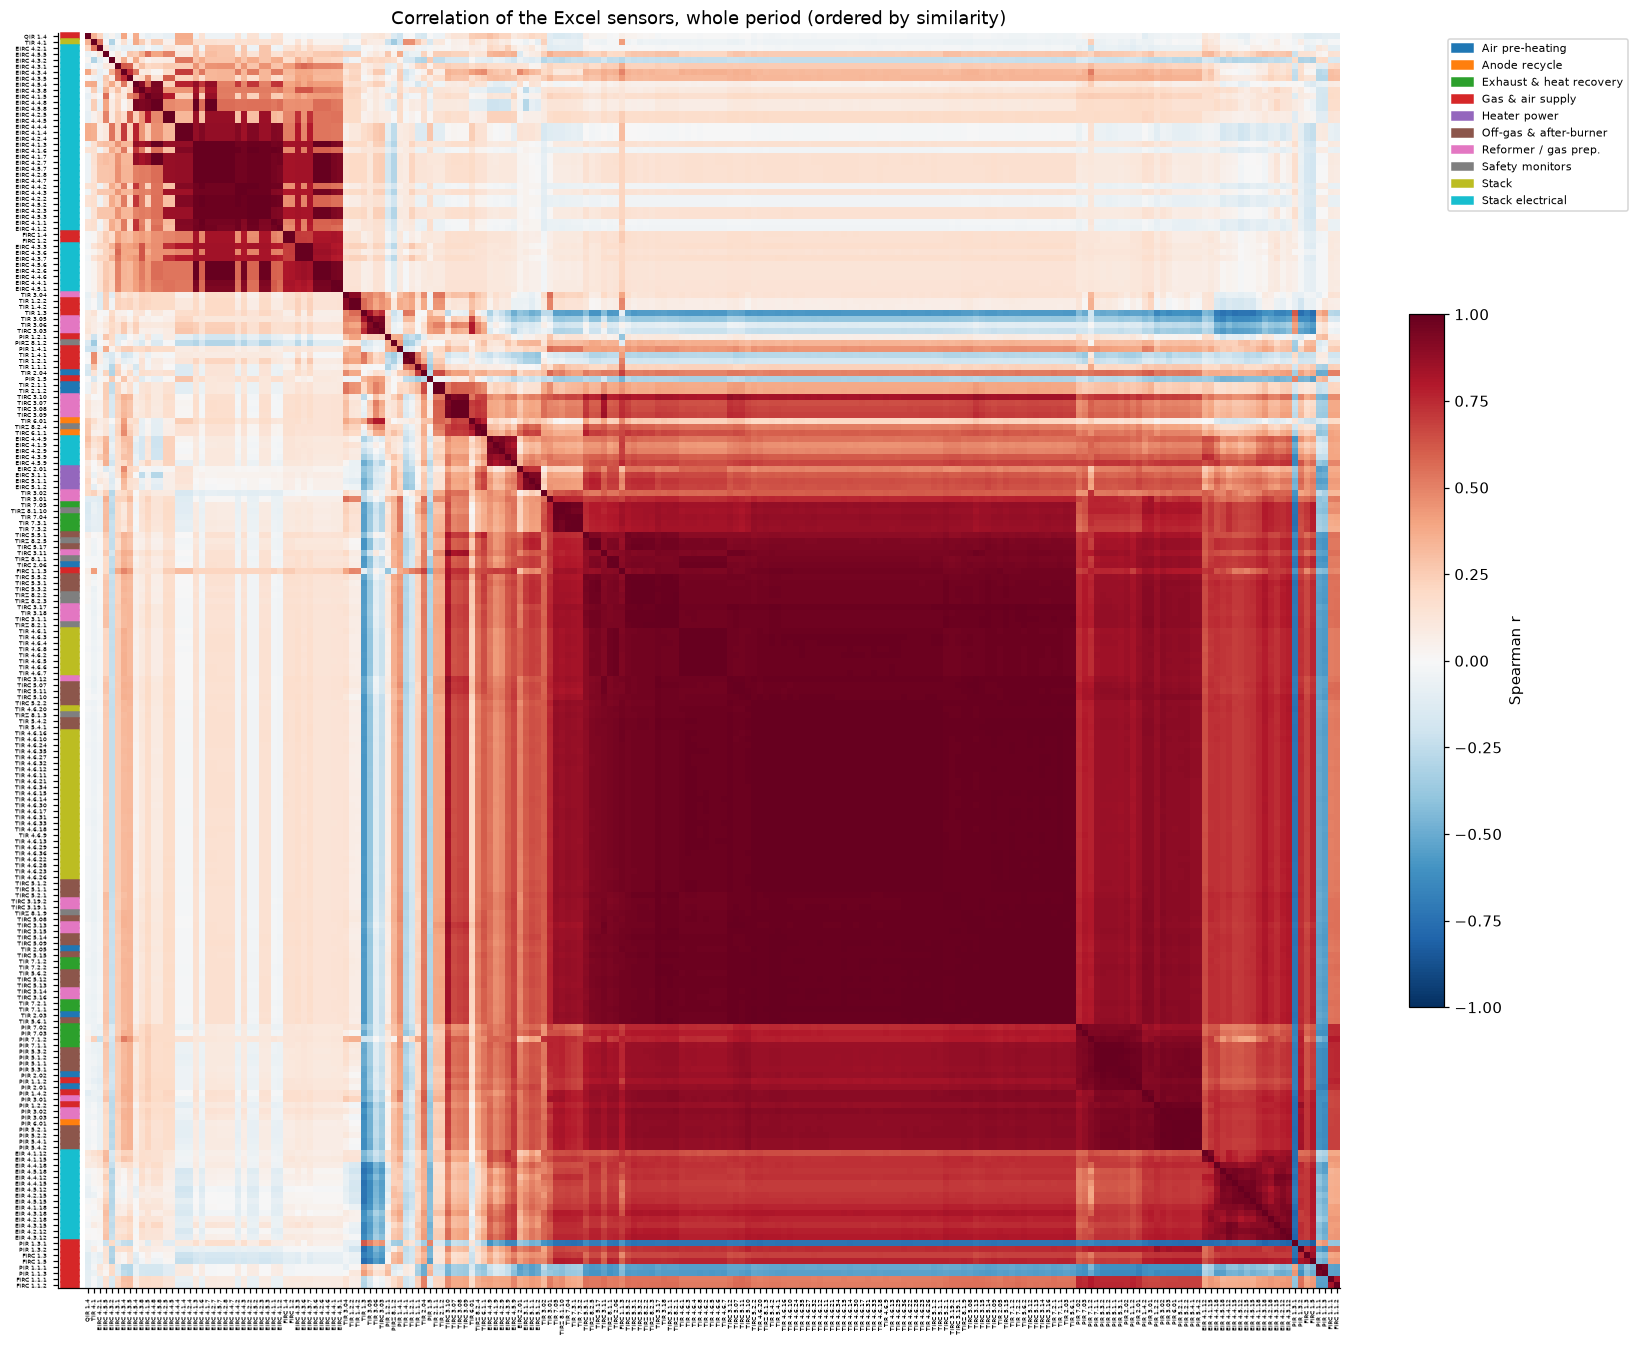

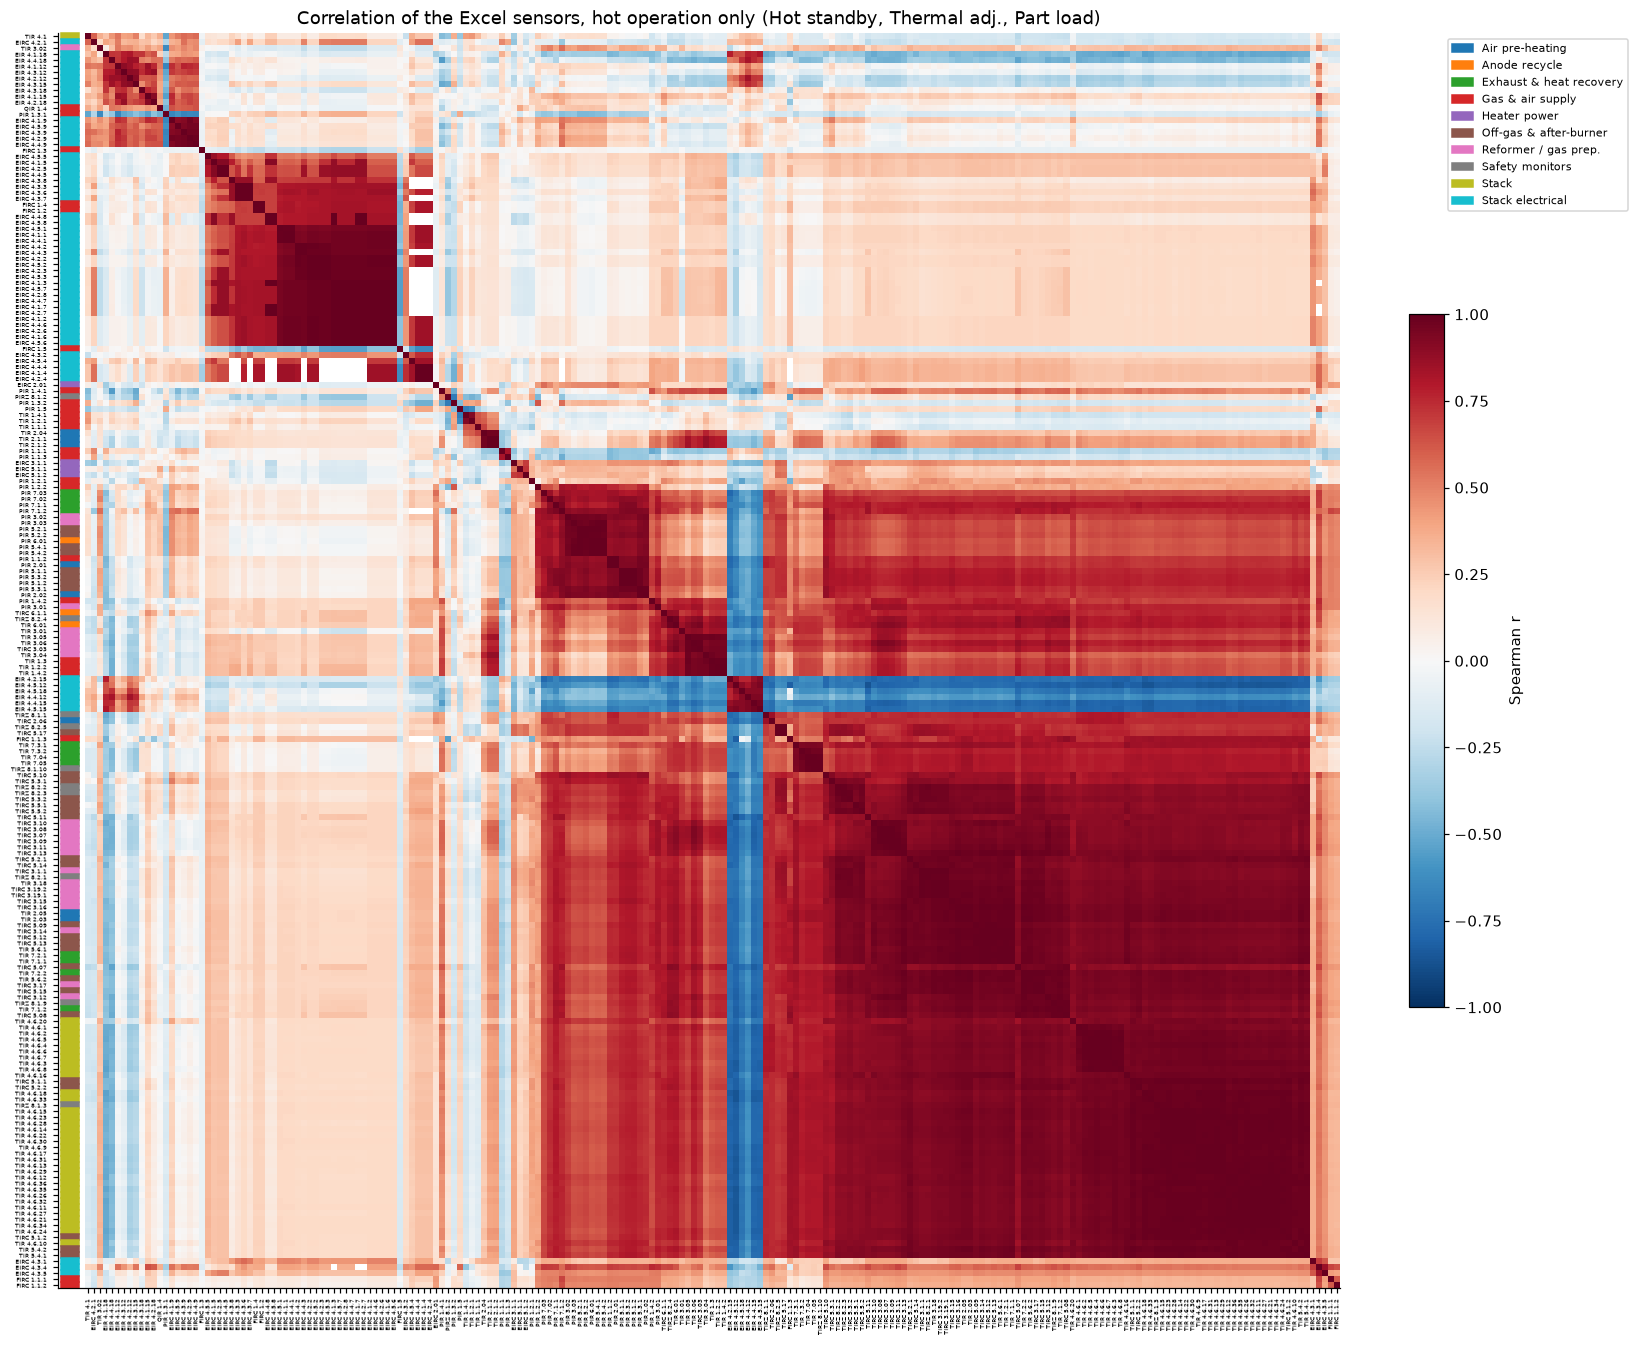

In [14]:
from scipy.cluster.hierarchy import leaves_list, linkage
from scipy.spatial.distance import squareform
from matplotlib.patches import Patch

AREA_COL = dict(zip(sorted(q.area.unique()), plt.cm.tab10.colors))


def corr_map(m, title, fname):
    m = m.dropna(how="all").dropna(how="all", axis=1)
    keep = m.index.intersection(m.columns)
    m = m.loc[keep, keep]
    d = (1 - m.abs().fillna(0)).to_numpy().copy()
    np.fill_diagonal(d, 0)
    o = leaves_list(linkage(squareform(d, checks=False), "average"))
    mo = m.iloc[o, o]
    fig, ax = plt.subplots(figsize=(15, 14))
    im = ax.imshow(mo.values, cmap="RdBu_r", vmin=-1, vmax=1, interpolation="nearest")
    t = [col2tag.get(c, c) for c in mo.index]
    ax.set_xticks(range(len(t)), t, rotation=90, fontsize=4.2)
    ax.set_yticks(range(len(t)), t, fontsize=4.2)
    areas = q.drop_duplicates("column").set_index("column").area.reindex(mo.index)
    for i, a in enumerate(areas):
        ax.add_patch(plt.Rectangle((-4.5, i - .5), 3, 1, color=AREA_COL.get(a, "k"), clip_on=False))
    ax.set_xlim(-5, len(t) - .5)
    ax.legend(handles=[Patch(color=c, label=a) for a, c in AREA_COL.items()], fontsize=7, loc="upper left",
              bbox_to_anchor=(1.08, 1))
    plt.colorbar(im, ax=ax, fraction=.025, label="Spearman r")
    ax.set_title(title)
    plt.tight_layout()
    fig.savefig(OUT / fname, dpi=130)
    plt.show()
    return mo


MO = corr_map(S, "Correlation of the Excel sensors, whole period (ordered by similarity)", "correlation_all.png")
MH = corr_map(SH, "Correlation of the Excel sensors, hot operation only (Hot standby, Thermal adj., Part load)", "correlation_hot.png")

### 5.2 Correlation between plant areas

Median |r| between all sensors of one area and all sensors of another (diagonal = inside one area).

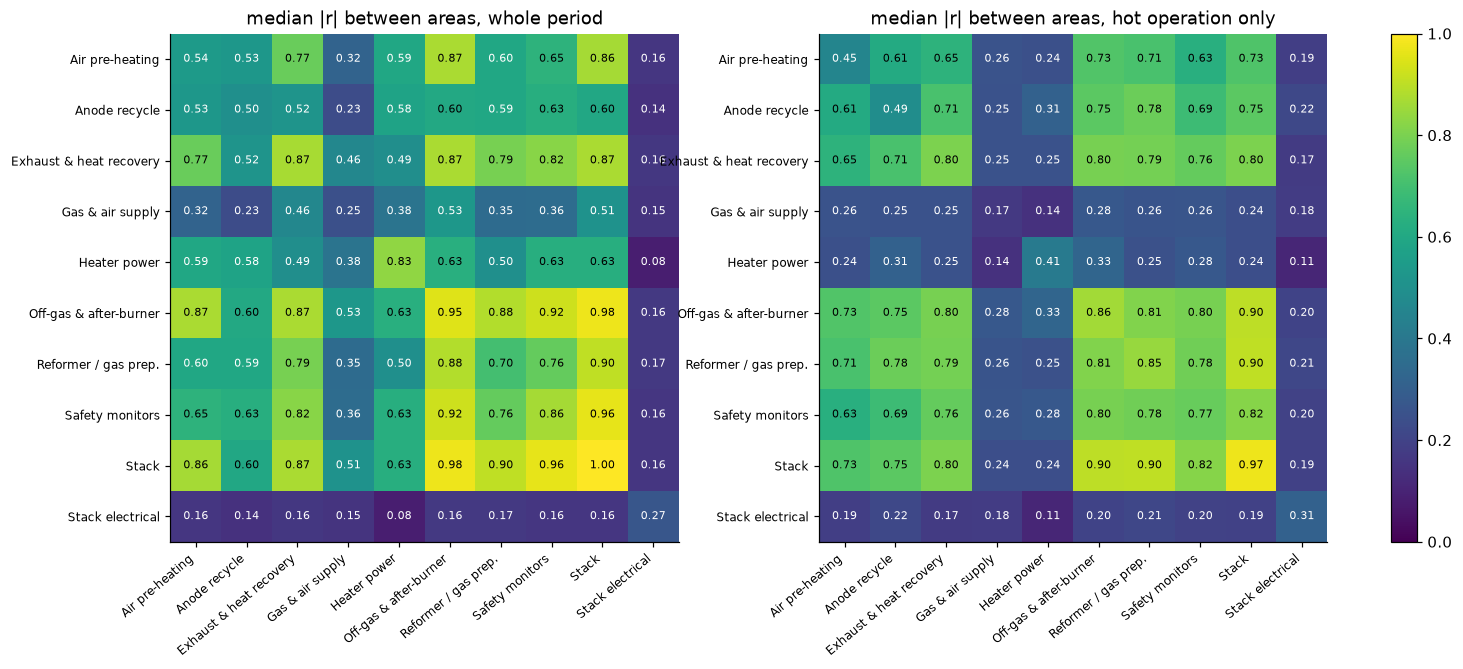

In [15]:
area_of = q.drop_duplicates("column").set_index("column").area


def area_matrix(m):
    a = area_of.reindex(m.index)
    names = sorted(a.dropna().unique())
    out = pd.DataFrame(index=names, columns=names, dtype=float)
    for x in names:
        for y in names:
            blk = m.loc[a[a == x].index, a[a == y].index].abs()
            if x == y:
                blk = blk.where(~np.eye(len(blk), dtype=bool))
            out.loc[x, y] = np.nanmedian(blk.values) if blk.notna().any().any() else np.nan
    return out


AM, AH = area_matrix(S), area_matrix(SH)
fig, axs = plt.subplots(1, 2, figsize=(15, 6))
for ax, m, ttl in [(axs[0], AM, "whole period"), (axs[1], AH, "hot operation only")]:
    im = ax.imshow(m.values.astype(float), cmap="viridis", vmin=0, vmax=1)
    ax.set_xticks(range(len(m)), m.columns, rotation=40, ha="right", fontsize=8)
    ax.set_yticks(range(len(m)), m.index, fontsize=8)
    for i in range(len(m)):
        for j in range(len(m)):
            v = m.values[i, j]
            if np.isfinite(v):
                ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if v < .6 else "black")
    ax.set_title(f"median |r| between areas, {ttl}")
plt.colorbar(im, ax=axs, fraction=.02)
fig.savefig(OUT / "correlation_areas.png", dpi=130, bbox_inches="tight")
plt.show()

### 5.3 Each sensor against the three main drivers

Correlation of every sensor with the **stack temperature** (mean of the stack thermocouples `TIR 4,6,x`), the **string current** (`EIRC 4,x,2`, mean of 5 strings) and the **cathode air flow** (`FIRC 1,1,1`). Whole period and hot operation only.

In [16]:
tc_cols = [c for c in okc if col2tag.get(c, "").startswith("TIR 4,6,") and col2tag[c] not in set(P.tag)]
cur_cols = [c for c in okc if re.match(r"EIRC 4,\d,2$", col2tag.get(c, ""))]
drivers = pd.DataFrame({"stack temperature": Y[tc_cols].mean(axis=1),
                        "string current": Y[cur_cols].mean(axis=1) if cur_cols else np.nan,
                        "cathode air flow": num[qt.at["FIRC 1,1,1", "column"]].iloc[::10]})
rk, rkh = Y.rank(), Y[hot.values].rank()
DR = pd.DataFrame({f"{d} ({w})": (rk if w == "all" else rkh).corrwith((drivers if w == "all" else drivers[hot.values])[d].rank())
                   for d in drivers for w in ("all", "hot")})
DR.index = [col2tag.get(c, c) for c in DR.index]
DR.insert(0, "area", [area_of.get(c) for c in okc])
DR.round(3).to_csv(OUT / "correlation_drivers.csv")
with pd.option_context("display.max_rows", 300):
    display(DR.round(2).sort_values(["area", "stack temperature (all)"], ascending=[True, False]))

,area,stack temperature (all),stack temperature (hot),string current (all),string current (hot),cathode air flow (all),cathode air flow (hot)
"TIR 2,05",Air pre-heating,0.99,0.96,-0.23,0.23,0.52,0.37
"TIR 2,03",Air pre-heating,0.99,0.96,-0.23,0.23,0.54,0.37
"TIRC 2,06",Air pre-heating,0.96,0.76,-0.25,0.15,0.52,0.37
"PIR 2,01",Air pre-heating,0.87,0.73,-0.21,0.13,0.74,0.52
"PIR 2,02",Air pre-heating,0.87,0.73,-0.20,0.12,0.75,0.51
"TIR 2,04",Air pre-heating,0.50,0.27,-0.30,-0.07,0.51,0.05
"TIR 2,1,1",Air pre-heating,0.38,0.40,-0.24,-0.03,0.21,0.11
"TIR 2,1,2",Air pre-heating,0.38,0.41,-0.25,-0.03,0.21,0.12
"PIR 6,01",Anode recycle,0.89,0.63,-0.28,0.07,0.68,0.50
"TIRC 6,1,1",Anode recycle,0.61,0.76,-0.11,0.18,0.40,0.39


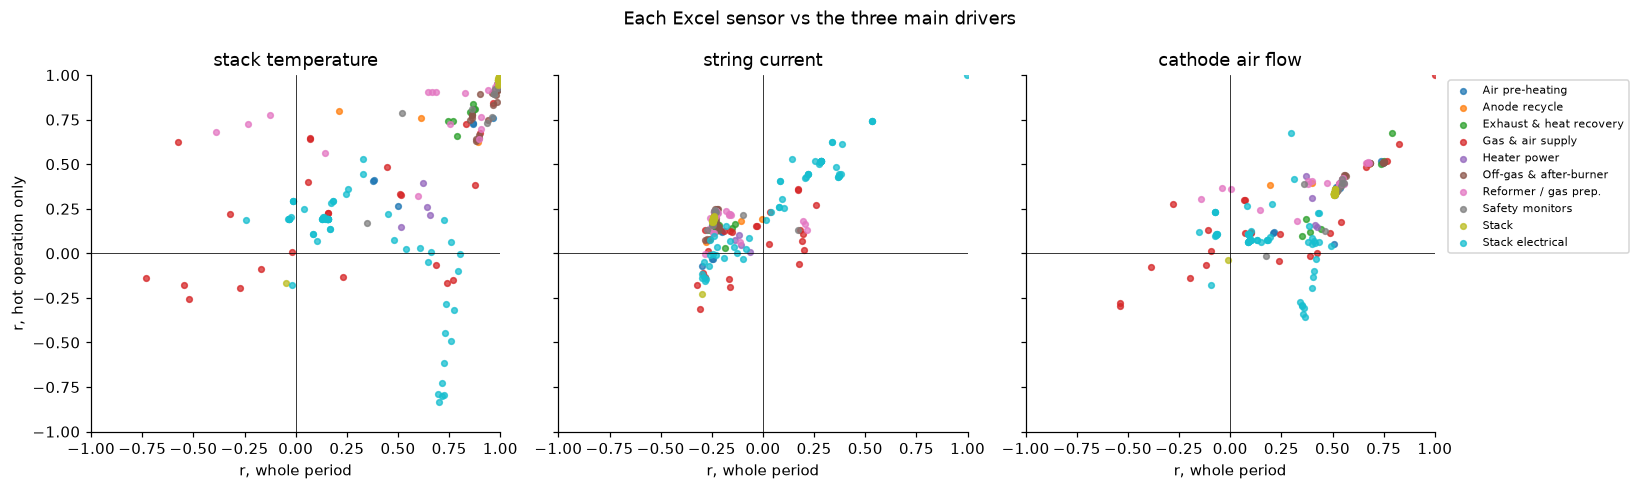

In [17]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, d in zip(axs, drivers.columns):
    for a, g in DR.groupby("area"):
        ax.scatter(g[f"{d} (all)"], g[f"{d} (hot)"], s=14, alpha=.75, color=AREA_COL.get(a), label=a)
    ax.axhline(0, color="k", lw=.5); ax.axvline(0, color="k", lw=.5)
    ax.set_xlim(-1, 1); ax.set_ylim(-1, 1)
    ax.set_xlabel("r, whole period"); ax.set_title(d)
axs[0].set_ylabel("r, hot operation only")
axs[-1].legend(fontsize=7, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.suptitle("Each Excel sensor vs the three main drivers")
plt.tight_layout()
fig.savefig(OUT / "correlation_drivers.png", dpi=130)
plt.show()

### 5.4 Strongest links between different areas

Pairs from two different plant areas, ranked by |r|. Whole-period pairs mostly show the common hot/cold swing; the hot-operation list shows the links that survive inside operation (for example heater temperatures driving downstream temperatures, or gas flows following the load).

In [18]:
def cross_pairs(m, n=25):
    u = up(m).rename("r").reset_index()
    u.columns = ["a", "b", "r"]
    u["area_a"], u["area_b"] = u.a.map(area_of), u.b.map(area_of)
    u = u[u.area_a != u.area_b]
    u["tag_a"], u["tag_b"] = u.a.map(col2tag), u.b.map(col2tag)
    return u.reindex(u.r.abs().sort_values(ascending=False).index)[["tag_a", "area_a", "tag_b", "area_b", "r"]].head(n).round(3)


print("Whole period")
display(cross_pairs(S))
print("Hot operation only")
display(cross_pairs(SH))
print("Strongest negative pairs, hot operation only")
uh = up(SH).rename("r").reset_index(); uh.columns = ["a", "b", "r"]
uh = uh.sort_values("r").head(15)
display(pd.DataFrame({"tag_a": uh.a.map(col2tag), "area_a": uh.a.map(area_of), "tag_b": uh.b.map(col2tag),
                      "area_b": uh.b.map(area_of), "r": uh.r.round(3)}))

Whole period


,tag_a,area_a,tag_b,area_b,r
8872,"TIR 7,1,1",Exhaust & heat recovery,"TIRC 3,14",Reformer / gas prep.,0.999
8861,"TIR 7,1,1",Exhaust & heat recovery,"TIRC 5,12",Off-gas & after-burner,0.999
26893,"TIR 4,6,24",Stack,"TIRC 5,1,2",Off-gas & after-burner,0.999
27311,"TIR 4,6,27",Stack,"TIRC 5,1,2",Off-gas & after-burner,0.999
25223,"TIR 4,6,15",Stack,"TIRC 5,1,1",Off-gas & after-burner,0.999
28356,"TIR 4,6,32",Stack,"TIRC 5,1,2",Off-gas & after-burner,0.999
10082,"TIR 7,2,2",Exhaust & heat recovery,"TIR 5,6,2",Off-gas & after-burner,0.999
28147,"TIR 4,6,31",Stack,"TIRC 5,1,2",Off-gas & after-burner,0.999
17441,"TIRC 5,12",Off-gas & after-burner,"TIRC 3,14",Reformer / gas prep.,0.999
25641,"TIR 4,6,17",Stack,"TIRC 5,1,1",Off-gas & after-burner,0.999


Hot operation only


,tag_a,area_a,tag_b,area_b,r
17441,"TIRC 5,12",Off-gas & after-burner,"TIRC 3,14",Reformer / gas prep.,0.997
8454,"TIR 7,2,1",Exhaust & heat recovery,"TIRC 3,14",Reformer / gas prep.,0.997
10082,"TIR 7,2,2",Exhaust & heat recovery,"TIR 5,6,2",Off-gas & after-burner,0.997
17650,"TIRC 5,13",Off-gas & after-burner,"TIRC 3,14",Reformer / gas prep.,0.996
8872,"TIR 7,1,1",Exhaust & heat recovery,"TIRC 3,14",Reformer / gas prep.,0.996
8401,"TIR 7,2,1",Exhaust & heat recovery,"TIR 5,6,1",Off-gas & after-burner,0.996
9073,"TIRC 3,17",Reformer / gas prep.,"TIRC 5,15",Off-gas & after-burner,0.996
8443,"TIR 7,2,1",Exhaust & heat recovery,"TIRC 5,12",Off-gas & after-burner,0.996
20581,"TIRC 3,1,1",Reformer / gas prep.,"TIRZ 8,2,1",Safety monitors,0.995
7351,"TIR 7,05",Exhaust & heat recovery,"TIRZ 8,1,10",Safety monitors,0.995


Strongest negative pairs, hot operation only


,tag_a,area_a,tag_b,area_b,r
25865,"TIR 4,6,18",Stack,"EIR 4,5,12",Stack electrical,-0.867
17296,"TIRC 5,11",Off-gas & after-burner,"EIR 4,5,12",Stack electrical,-0.862
28582,"TIR 4,6,33",Stack,"EIR 4,5,12",Stack electrical,-0.860
29000,"TIR 4,6,35",Stack,"EIR 4,5,12",Stack electrical,-0.857
24402,"TIR 4,6,11",Stack,"EIR 4,5,12",Stack electrical,-0.854
28373,"TIR 4,6,32",Stack,"EIR 4,5,12",Stack electrical,-0.849
27119,"TIR 4,6,26",Stack,"EIR 4,5,12",Stack electrical,-0.847
27746,"TIR 4,6,29",Stack,"EIR 4,5,12",Stack electrical,-0.847
26910,"TIR 4,6,24",Stack,"EIR 4,5,12",Stack electrical,-0.847
27328,"TIR 4,6,27",Stack,"EIR 4,5,12",Stack electrical,-0.847


## 6. Redundancy: how many independent signals are there?

From the whole-period Spearman matrix above: tags with |r| ≥ 0.95 are joined into one group (if A ≈ B and B ≈ C, all three are one group). The same is repeated for hot operation only, where fewer pairs are that close.

In [19]:
okc = np.array(okc)
A = S.abs().fillna(0).to_numpy().copy()
np.fill_diagonal(A, 0)
parent = list(range(len(okc)))


def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return i


for i, j in zip(*np.where(A >= .95)):
    parent[find(i)] = find(j)
root = pd.Series([find(i) for i in range(len(okc))], index=okc)
size = root.map(root.value_counts())
gid = {k: n + 1 for n, k in enumerate(root.value_counts().index)}
col2tag = q.drop_duplicates("column").set_index("column").tag
G = pd.DataFrame({"tag": col2tag.reindex(okc).values, "group": root.map(gid).values, "group_size": size.values,
                  "most_like": [col2tag.get(S.columns[i], S.columns[i]) for i in A.argmax(1)],
                  "r": A.max(1).round(3)}, index=okc)
print(f"{len(okc)} usable columns form {G.group.nunique()} independent groups at |r| ≥ 0.95 (whole period);",
      f"{(G.group_size == 1).sum()} stand alone")
AH_ = SH.abs().fillna(0).to_numpy().copy()
np.fill_diagonal(AH_, 0)
parent = list(range(len(okc)))
for i, j in zip(*np.where(AH_ >= .95)):
    parent[find(i)] = find(j)
n_hot = len({find(i) for i in range(len(okc))})
print("hot operation only:", n_hot, "groups at |r| ≥ 0.95")
parent = list(range(len(okc)))
big = G[G.group_size > 1].groupby("group").agg(size=("tag", "size"), tags=("tag", lambda x: ", ".join(sorted(x)[:8]) + (" …" if len(x) > 8 else "")))
display(big.sort_values("size", ascending=False).head(20))
G.to_csv(OUT / "groups.csv")

209 usable columns form 56 independent groups at |r| ≥ 0.95 (whole period); 39 stand alone
hot operation only: 75 groups at |r| ≥ 0.95


,size,tags
group,,
1,82,"FIRC 1,1,3, TIR 2,03, TIR 2,05, TIR 3,18, TIR 4,6,1, TIR 4,6,10, TIR 4,6,11,..."
2,24,"EIRC 4,1,1, EIRC 4,1,2, EIRC 4,1,3, EIRC 4,1,5, EIRC 4,1,6, EIRC 4,1,7, EIRC..."
3,20,"PIR 1,1,2, PIR 1,2,2, PIR 1,4,2, PIR 2,01, PIR 2,02, PIR 3,01, PIR 3,02, PIR..."
4,11,"EIR 4,1,18, EIR 4,2,12, EIR 4,2,15, EIR 4,3,12, EIR 4,3,15, EIR 4,3,18, EIR ..."
5,5,"TIR 7,04, TIR 7,05, TIR 7,3,1, TIR 7,3,2, TIRZ 8,1,10"
6,4,"TIRC 3,07, TIRC 3,08, TIRC 3,09, TIRC 3,10"
7,3,"EIRC 4,1,4, EIRC 4,2,4, EIRC 4,4,4"
8,3,"EIRC 4,3,3, EIRC 4,3,6, EIRC 4,3,7"
9,2,"PIR 1,1,1, PIR 1,1,3"


## 7. Verdict per tag

Rules, applied in this order:
1. **Not traceable**: blank name or no matching column. **Duplicate row**: the tag already appears higher up.
2. **Not usable**: dead (moves on < 3 days), stuck thermocouple, a stack thermocouple reading far from the others, or a near-zero voltage channel.
3. **Limited**: real values only on part of the period: logged on fewer than 39 days, `-1` on more than half of the minutes (e.g. set-points while the load is idle), or `-1`/blank until a late first day.
4. **Back-up twin**: in a group of near-copies (|r| ≥ 0.98 both over the whole period and in hot operation, so a shared hot/cold swing alone does not count) and not the group's first tag in the Excel order; kept for safety checks and cross-checks, not needed for models.
5. **Key**: used by the stage rules, or η² ≥ 0.5 (the stage clearly shows in it), or one of two known operating limits that only act during load: the exhaust trip sensor `TIRZ 8,1,10` (8 of 10 part-load runs tripped on it) and the lowest cell voltage `EIRC 4,x,9` (the limit that capped part load), see `part_load_analysis.ipynb`.
6. **Useful**: η² 0.2–0.5. **Low value**: η² < 0.2 (barely changes between stages; e.g. supply pressures, room-temperature probes).

In [20]:
USED = {"TIR 4,6", "EIRC 4,1,2", "EIRC 4,2,2", "EIRC 4,3,2", "EIRC 4,4,2", "EIRC 4,5,2", "EIRC 2,01", "PIR 2,02",
        "FIRC 1,1,1", "FIRC 1,1,2", "FIRC 1,3", "FIRC 1,4", "FIRC 1,5", "TIR 1,1,1", "TIR 1,2,1", "TIR 1,3", "TIR 1,4,1"}
groups98 = {}
okA = (A >= .98) & (AH_ >= .98)
BOTH = np.minimum(A, AH_)
okidx = {c: i for i, c in enumerate(okc)}
partner = lambda c: (col2tag.get(okc[BOTH[okidx[c]].argmax()]), BOTH[okidx[c]].max())
parent = list(range(len(okc)))
for i, j in zip(*np.where(okA)):
    parent[find(i)] = find(j)
g98 = pd.Series([find(i) for i in range(len(okc))], index=okc)
leader = {}
for c in q.sort_values("sno").column:
    if c in g98.index:
        leader.setdefault(g98[c], c)
KNOWN = {"TIRZ 8,1,10": "exhaust trip sensor: 8 of 10 part-load runs tripped on it"}
KNOWN.update({f"EIRC 4,{k},9": "lowest cell voltage: the limit that capped part load (0.72–0.80 V)" for k in range(1, 6)})
probs = P.set_index("sno").problem if len(P) else pd.Series(dtype=str)

V = []
for _, r in T.sort_values("sno").iterrows():
    used = any(r.tag == u or (u == "TIR 4,6" and r.tag.startswith("TIR 4,6,")) for u in USED)
    pr = probs.get(r.sno, "")
    if r.how == "none":
        v, why = "Not traceable", r.meaning
    elif pd.notna(r.duplicate_of):
        v, why = "Duplicate row", f"same tag as row {int(r.duplicate_of)}"
    elif r.tag in BAD:
        v, why = "Not usable", pr
    elif r.days_logged < 39 or r.minus1_share > .5 or "real values only" in pr:
        v, why = "Limited", pr
    elif r.tag in KNOWN:
        v, why = "Key", KNOWN[r.tag] + f"; η² = {r.eta2_stage:.2f}"
    elif r.column in g98.index and leader[g98[r.column]] != r.column and not used:
        v, why = "Back-up twin", "moves with {} (|r| = {:.3f} over the whole period and in hot operation); group kept by {}".format(*partner(r.column), col2tag.get(leader[g98[r.column]]))
    elif used or r.eta2_stage >= .5:
        v, why = "Key", ("used in the stage rules; " if used else "") + f"η² = {r.eta2_stage:.2f}"
    elif r.eta2_stage >= .2:
        v, why = "Useful", f"η² = {r.eta2_stage:.2f}"
    else:
        v, why = "Low value", f"η² = {r.eta2_stage:.2f}: barely changes between stages"
    V.append(dict(sno=r.sno, tag=r.tag, area=r.area, kind=r.kind, column=r.column, how=r.how, meaning=r.meaning,
                  verdict=v, reason=why, used_in_stage_rules=used, days_logged=r.days_logged,
                  coverage_pct=round(100 * r.coverage, 1) if pd.notna(r.coverage) else None,
                  minus1_pct=round(100 * r.minus1_share, 1) if pd.notna(r.minus1_share) else None,
                  days_moving=r.days_moving, eta2_stage=round(r.eta2_stage, 3) if pd.notna(r.eta2_stage) else None,
                  p01=r.p01, median=r["median"], p99=r.p99, **{f"med_{k}": r[f"med_{k}"] for k in STAGES},
                  group=G.group.get(r.column) if r.column in G.index else None))
V = pd.DataFrame(V)
V.to_csv(OUT / "verdict.csv", index=False)
ORDER_V = ["Key", "Useful", "Low value", "Back-up twin", "Limited", "Not usable", "Duplicate row", "Not traceable"]
display(pd.crosstab(V.area, V.verdict, margins=True, margins_name="Total")[[c for c in ORDER_V if c in set(V.verdict)] + ["Total"]])

verdict,Key,Useful,Low value,Back-up twin,Limited,Not usable,Duplicate row,Not traceable,Total
area,,,,,,,,,
Air pre-heating,3,2,1,2,0,0,0,0,8
Anode recycle,2,1,0,0,0,0,0,0,3
Exhaust & heat recovery,0,6,0,5,1,0,0,1,13
Gas & air supply,10,4,7,2,1,0,0,0,24
Heater power,4,0,0,0,0,0,1,0,5
Off-gas & after-burner,7,2,0,21,0,0,0,0,30
Reformer / gas prep.,2,7,2,13,0,0,1,0,25
Safety monitors,4,1,1,4,0,0,0,0,10
Stack,34,0,1,0,0,2,0,0,37


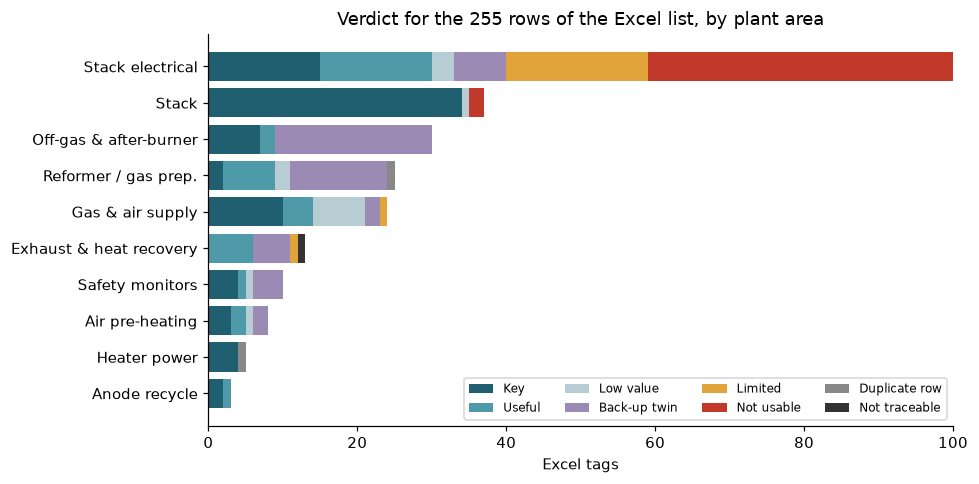

In [21]:
cnt = pd.crosstab(V.area, V.verdict)[[c for c in ORDER_V if c in set(V.verdict)]]
cnt = cnt.loc[cnt.sum(axis=1).sort_values().index]
colors = {"Key": "#1f5f70", "Useful": "#4f9aa8", "Low value": "#b7cdd3", "Back-up twin": "#9b8bb4",
          "Limited": "#e0a43a", "Not usable": "#c0392b", "Duplicate row": "#888888", "Not traceable": "#333333"}
fig, ax = plt.subplots(figsize=(9, 4.5))
left = np.zeros(len(cnt))
for c in cnt.columns:
    ax.barh(cnt.index, cnt[c], left=left, color=colors[c], label=c)
    left += cnt[c].values
ax.legend(ncol=4, fontsize=8, loc="lower right")
ax.set_xlabel("Excel tags")
ax.set_title(f"Verdict for the {len(V)} rows of the Excel list, by plant area")
plt.tight_layout()
fig.savefig(OUT / "verdict_by_area.png", dpi=130)
plt.show()

In [22]:
for v in ["Not usable", "Limited", "Not traceable", "Duplicate row"]:
    s = V[V.verdict == v]
    print(f"\n{v} ({len(s)})")
    display(s[["sno", "tag", "area", "column", "reason"]])


Not usable (43)


,sno,tag,area,column,reason
127,128,"TIR 4,6,19",Stack,TIR_4_6_19,dead: moves on 1 days; median 1300 °C vs 407 °C for the other stack thermoco...
133,134,"TIR 4,6,25",Stack,TIR_4_6_25,median 36 °C vs 407 °C for the other stack thermocouples
151,152,"EIR 4,1,10",Stack electrical,pi_EIR_4_1_10,near zero: median 0.0057 V; above 0.5 V on only 2 days
152,153,"EIR 4,1,11",Stack electrical,pi_EIR_4_1_11,near zero: median 0.0004 V; above 0.5 V on only 1 days
154,155,"EIR 4,1,13",Stack electrical,pi_EIR_4_1_13,near zero: median 0.0055 V; above 0.5 V on only 1 days
155,156,"EIR 4,1,14",Stack electrical,pi_EIR_4_1_14,near zero: median 0.0010 V; above 0.5 V on only 1 days
157,158,"EIR 4,1,16",Stack electrical,pi_EIR_4_1_16,near zero: median 0.0064 V; above 0.5 V on only 1 days
158,159,"EIR 4,1,17",Stack electrical,pi_EIR_4_1_17,near zero: median 0.0034 V; above 0.5 V on only 2 days
160,161,"EIR 4,1,19",Stack electrical,pi_EIR_4_1_19,near zero: median 0.0042 V; above 0.5 V on only 1 days
161,162,"EIR 4,1,20",Stack electrical,pi_EIR_4_1_20,near zero: median 0.0021 V; above 0.5 V on only 2 days



Limited (21)


,sno,tag,area,column,reason
3,4,"FIRC 1,1,3",Gas & air supply,ct_FIRC_113_PV_ProcessValue,logged on 12 of 39 days
48,49,"PIR 7,1,2",Exhaust & heat recovery,PIR_7_1_2,mostly -1 (50% of minutes); real values only from 2026-02-17 (-1 or blank be...
208,209,"EIRC 4,1,3",Stack electrical,EIRC_41_Actual_Power,logged on 12 of 39 days; 10 invalid values
209,210,"EIRC 4,1,4",Stack electrical,PLC_hostSetp_ctrl_ctEIRC41_SP_TargetValue_Value,mostly -1 (58% of minutes); real values only from 2026-02-06 (-1 or blank be...
212,213,"EIRC 4,1,7",Stack electrical,EIRC_41_OUT_Enable,logged on 12 of 39 days; 3948 invalid values
217,218,"EIRC 4,2,3",Stack electrical,EIRC_42_Actual_Power,logged on 12 of 39 days
218,219,"EIRC 4,2,4",Stack electrical,PLC_hostSetp_ctrl_ctEIRC42_SP_TargetValue_Value,mostly -1 (58% of minutes); real values only from 2026-02-06 (-1 or blank be...
221,222,"EIRC 4,2,7",Stack electrical,EIRC_42_OUT_Enable,logged on 12 of 39 days
222,223,"EIRC 4,2,8",Stack electrical,EIRC_42_OUT_StackCon_OnOff),logged on 12 of 39 days
226,227,"EIRC 4,3,3",Stack electrical,EIRC_43_Actual_Power,logged on 12 of 39 days



Not traceable (1)


,sno,tag,area,column,reason
33,34,"LIR 7,01",Exhaust & heat recovery,NaN,no such column in the 836 logged columns



Duplicate row (2)


,sno,tag,area,column,reason
54,55,"TIRC 3,17",Reformer / gas prep.,TIRC_3_17,same tag as row 45
63,64,"EIRC 2,01",Heater power,EIRC_2_01_ActV_In_ThreePhasePower,same tag as row 29


## 8. Summary numbers

In [23]:
nu = V[V.verdict == "Not usable"]
summary = {
    "Excel rows / distinct tags": f"{len(V)} / {V.tag.nunique()}",
    "traced to a raw column (same name / other name / assumed)": f"{(V.how != 'none').sum()} ({(V.how == 'direct').sum()} / {(V.how == 'other name').sum()} / {(V.how == 'assumed').sum()})",
    "not in the raw data": ", ".join(V[V.how == "none"].tag),
    "raw measurement columns missing from the Excel list": len(EX),
    "verdicts": V.verdict.value_counts().to_dict(),
    "not usable: EIR package voltages near 0 V": int(nu.reason.str.contains("near zero").sum()),
    "sensors in the correlation": len(okc),
    "independent groups at |r| ≥ 0.95, whole period / hot only": f"{G.group.nunique()} / {n_hot}",
}
for k, v in summary.items():
    print(f"{k}: {v}")

Excel rows / distinct tags: 255 / 253
traced to a raw column (same name / other name / assumed): 254 (201 / 35 / 18)
not in the raw data: LIR 7,01
raw measurement columns missing from the Excel list: 38
verdicts: {'Key': 81, 'Back-up twin': 54, 'Not usable': 43, 'Useful': 38, 'Limited': 21, 'Low value': 15, 'Duplicate row': 2, 'Not traceable': 1}
not usable: EIR package voltages near 0 V: 40
sensors in the correlation: 209
independent groups at |r| ≥ 0.95, whole period / hot only: 56 / 75


## 9. Findings

**Names (§1, §1b)**
- Most tags keep their name in the raw data with `,` → `_` (`TIR 4,6,1` → `TIR_4_6_1`). The exceptions are the flows (`FIRC 1,1,1` → `ct_FIRC_111_PV_ProcessValue`), the electronic loads (`EIRC 4,s,k` → `PLC_hostSetp_ctrl_ctEIRC4s_…` or `EIRC_4s_…`), the heater power/currents and `TIRC 3,19,x` (logged as `TIR_3_19_x`). The full table is `excel_sensors/excel_to_raw_names.csv`.
- `EIRC 4,s,3/7/8` (load power, on/off, device status) and `FIRC 1,1,3` exist only from 2026-03-17 (12 files). Before that date `FIRC 1,1,3` was logged as `PLC_ctrl_ct_FIRC_113_PV_ProcessValue` (in the related-columns list).
- Missing from the Excel list but logged: `pi_EIR_4_s_21` (stack 4 voltage of every string, ≈ 100 V hot; the Excel list stops at stack 3), `pi_EIR_4_s_22` (meaning unknown), heater currents `pi_IIR_5_1_3` and `pi_IIR_6_1_1`, `TIR_2_02`, the `EIRC_4s_CurrentMon/VoltageMon/ActV_Min_CellVoltage` twins (from 2026-03-17), and `pi_QIR_10_23/24/25_Temp/RH/Press`: three climate sensors (temperature, humidity, barometric pressure ≈ 990–1013 hPa). These are worth checking as a true **ambient** reference, which the stage rules currently approximate with the fuel-line probes.

**Quality (§3)**
- Coverage is ≈ 100 % on all 39 days for 238 of 254 traced tags; the rest are the 12-day columns.
- A `-1` on about 0.1 % of the minutes of almost every channel is the logger-dropout minute (2026-02-18, 03-13, 03-17), not a sensor fault; it should be blanked.
- `-1` on more than half of the minutes: the load set-points `EIRC 4,s,4` (they read `-1` whenever the load controller is idle) and `PIR 7,1,2` (not connected until 2026-02-17).
- Natural gas `FIRC 1,4`, POx air `FIRC 1,2` and the load signals first move in February/March because the plant first used them then; before that they read a valid 0.

**Stages (§4)**
- The stage shows most clearly in the load signals (η² ≈ 0.85, but only in the 4.5 h of Part load), the heater power (0.66), the safety, stack and off-gas temperatures (≈ 0.6). Supply pressures and the room-temperature probes barely change between stages (η² < 0.2).
- The flows give a clean phase signature: forming gas (`FIRC 1,3` 1200 + `FIRC 1,5` 60 ln/min) in Start-up, Hot standby and Thermal adjustment; natural gas (`FIRC 1,4` ≈ 140) with POx air (`FIRC 1,2` ≈ 310) only in Part load; cathode air 3000 ln/min per blower, 4500 in Part load, off in Idle.

**Correlation (§5, §6)**
- Over the whole period the median |r| is 0.50 and 107 of 209 sensors follow the stack temperature with |r| ≥ 0.8: the plant heats and cools as one body. Inside hot operation the median |r| drops to 0.34 but 88 sensors still follow the stack temperature, because the heater temperatures drive everything downstream.
- The load hardly appears in the correlations (only 4.5 h with current), so relations with current cannot be learned from this data yet.
- Near-copies: the reformer, off-gas and exhaust temperatures along one flow path move together with |r| ≈ 0.99 even in hot operation; control/safety pairs (`TIR 7,05` ↔ `TIRZ 8,1,10`, `TIRC 5,17` ↔ `TIRZ 8,2,5`) and line-1/line-2 pairs are 1:1. 56 groups at |r| ≥ 0.95 (75 in hot operation) is a fair count of the independent signals.
- Stack voltages in hot operation (no or little load, so close to open-circuit voltage): strings 4 and 5 fall when the stack gets hotter (all three stacks, r = −0.45 to −0.83; also `EIR 4,2,15` −0.80), while strings 1 and 3 hardly react (r = −0.10 to +0.18). Over the whole period all of them rise with temperature (r ≈ 0.7–0.8, 0 V cold, ≈ 110 V hot). A voltage that drops as the hot stack warms fits the internal-leakage note in `operational-modes.md` §6.7; that it shows mainly in strings 4 and 5 is worth checking with IKTS.

**Use**
- For stage separation the current set is enough (stack temperatures, string current, heater power, air flow / inlet pressure, gas flows, ambient proxy).
- For models and synthetic data use one sensor per group (`groups.csv`, verdict *Key* or *Useful*); the *Back-up twin* tags can be rebuilt from their partner.
- Fix at the source or drop: the 40 EIR package-voltage channels, `TIR 4,6,19`, `TIR 4,6,25`; add the stack-4 voltages and check the `QIR 10,2x` climate sensors as ambient.